In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import mlflow
import mlflow.sklearn
from dotenv import load_dotenv
import os

In [25]:
load_dotenv()

#mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI"))
mlflow.set_tracking_uri(uri="http://127.0.0.1:5000")

In [26]:
mlflow.set_experiment("Titanic-RandomForest")

2026/10/10 12:44:27 INFO mlflow.tracking.fluent: Experiment with name 'Titanic-RandomForest' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791654267184, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791654267184, lifecycle_stage='active', name='Titanic-RandomForest', tags={}, trace_location=None, workspace='default'>

Paso 1: Carga y describe el dataset:

In [27]:
df = pd.read_csv("../data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [28]:
#Dimensiones y estructura del dataframe
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [29]:
#Cuales columnas tienen valores faltantes o nulos que se deben depurar
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


Paso 2. Limpieza de datos (Data Cleaning):

In [31]:

# Creacion de grupos com relacion a 'Age', 'Sex', 'Pclass' para relacionar a personas similares y poder rellenar los valores faltantes en 'Age''
df['Age'] = df.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))

# Transformacion de 'Cabin' en variable binaria para saber si el pasajero tiene cabina (1) o si no tiene cabina (0), "tener cabina mayor status"
df['Cabin_known'] = df['Cabin'].notnull().astype(int)

# Se relleno los valores faltantes en la columna 'Embarked' por S (Southampton) ya que este puerto era el mas popular.
df['Embarked'] = df['Embarked'].fillna('S')

df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Cabin_known      0
dtype: int64

Paso 3. Analisis Univariable (estadisticas y visualizaciones).

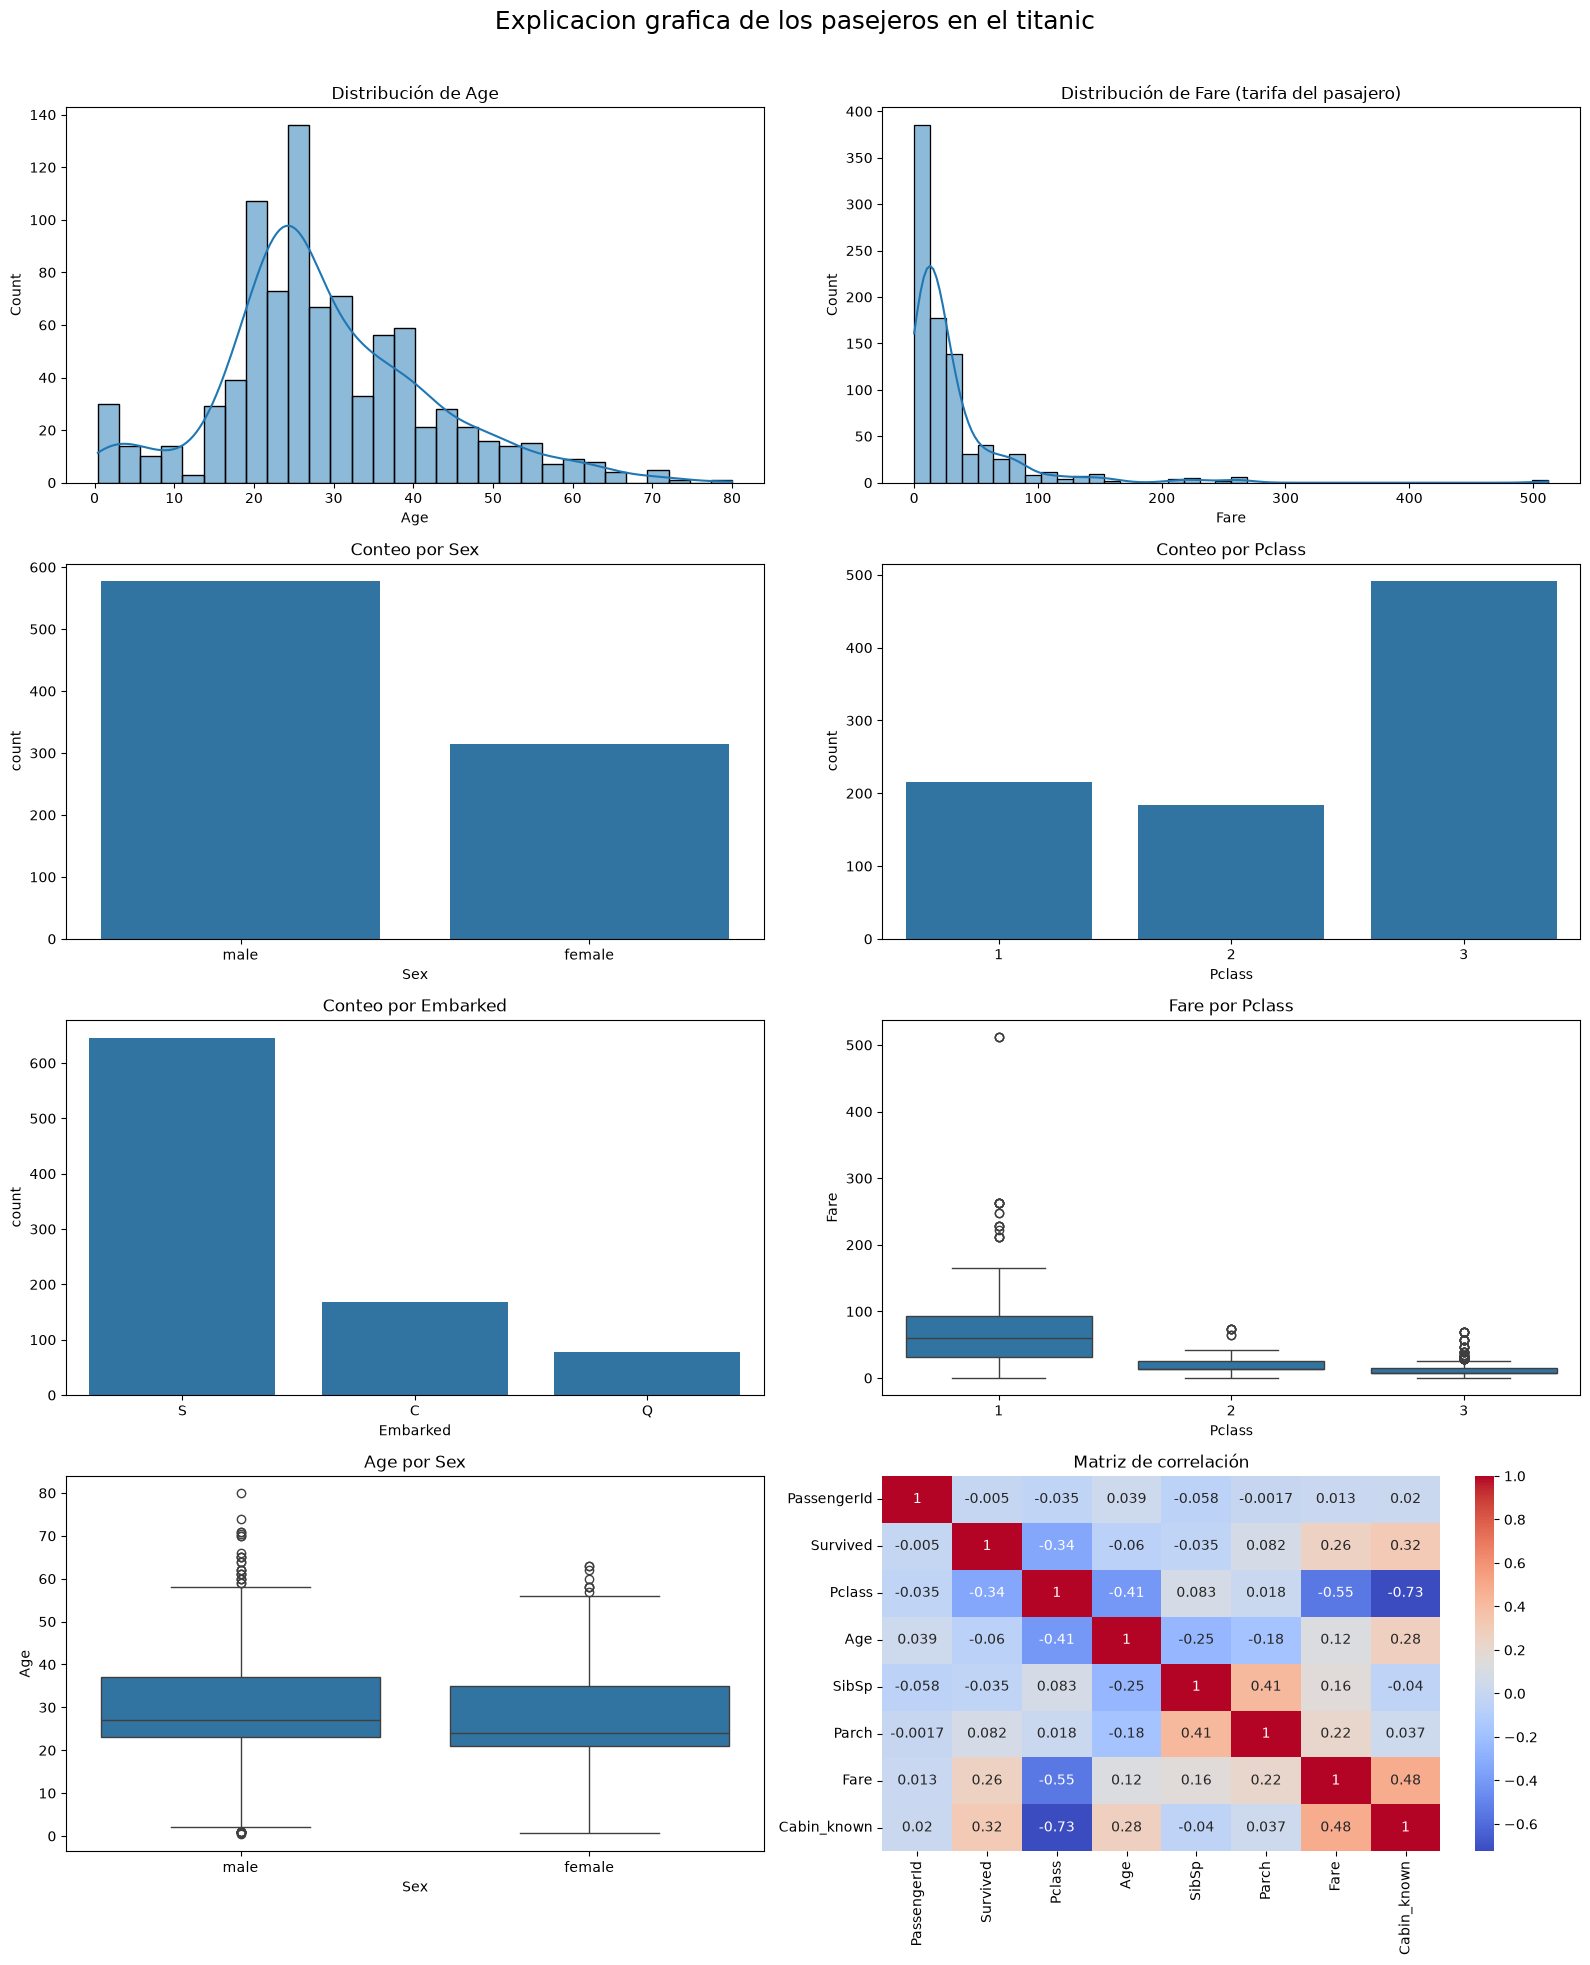

In [32]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle('Explicacion grafica de los pasejeros en el titanic', fontsize=18)

# 1. Age - Histograma
sns.histplot(df['Age'], bins=30, kde=True, ax=axes[0,0])
axes[0,0].set_title('Distribución de Age')

# 2. Fare - Histograma
sns.histplot(df['Fare'], bins=40, kde=True, ax=axes[0,1])
axes[0,1].set_title('Distribución de Fare (tarifa del pasajero)')

# 3. Sex - Conteo
sns.countplot(data=df, x='Sex', ax=axes[1,0])
axes[1,0].set_title('Conteo por Sex')

# 4. Pclass - Conteo
sns.countplot(data=df, x='Pclass', ax=axes[1,1])
axes[1,1].set_title('Conteo por Pclass')

# 5. Embarked - Conteo
sns.countplot(data=df, x='Embarked', ax=axes[2,0])
axes[2,0].set_title('Conteo por Embarked')

# 6. Fare por Pclass - Boxplot
sns.boxplot(data=df, x='Pclass', y='Fare', ax=axes[2,1])
axes[2,1].set_title('Fare por Pclass')

# 7. Age por Sex - Boxplot
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[3,0])
axes[3,0].set_title('Age por Sex')

# 8. Heatmap de correlación
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', ax=axes[3,1])
axes[3,1].set_title('Matriz de correlación')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Paso 4. Entrenar el modelo

In [33]:
#Copia del data frame limpio.
df_model = df.copy()

#One-hot encoding para variables categoricas.
df_model = pd.get_dummies(df_model, columns=['Sex', 'Embarked'], drop_first=True)

# Variables predictoras
X = df_model[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin_known',
              'Sex_male', 'Embarked_Q', 'Embarked_S']]

#Variable objetivo
y = df_model['Survived']

In [34]:
#Dividir en train/test
mlflow.sklearn.autolog()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [35]:
#Entrenar el modelo RandomForestClassifier
mlflow.start_run(run_name="RandomForest")

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

model.score(X_test, y_test)

2026/10/10 12:44:55 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\franc\apps\mna-baseline-mlflow\venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/10/10 12:44:55 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\franc\apps\mna-baseline-ml

0.8268156424581006

In [36]:
mlflow.end_run()

🏃 View run RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/beb6ad7e5da742ea8b7cbefa13c4bd0d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Loading Models

In [37]:
runs = mlflow.search_runs(
    search_all_experiments=True,
    order_by=["start_time DESC"],
    filter_string="status='FINISHED'"
)

In [38]:
runs

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.training_f1_score,metrics.training_score,metrics.training_recall_score,metrics.RandomForestClassifier_score_X_test,...,params.verbose,params.n_jobs,params.criterion,params.min_samples_leaf,tags.mlflow.source.type,tags.mlflow.user,tags.mlflow.source.name,tags.estimator_class,tags.estimator_name,tags.mlflow.runName
0,beb6ad7e5da742ea8b7cbefa13c4bd0d,1,FINISHED,mlflow-artifacts:/1/beb6ad7e5da742ea8b7cbefa13...,2026-10-10 17:44:55.558000+00:00,2026-10-10 17:45:02.037000+00:00,0.886364,0.889045,0.889045,0.826816,...,0,None,gini,2,NOTEBOOK,franc,3.01-FFPC-Titanic.ipynb,sklearn.ensemble._forest.RandomForestClassifier,RandomForestClassifier,RandomForest


In [39]:
run_id = runs.run_id[0]
model_uri = f"runs:/{run_id}/model"
loaded_model = mlflow.sklearn.load_model(model_uri)

In [40]:
loaded_model.predict(X_test)

array([0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 1])

Paso 5. Evalua el modelo

In [41]:
#Hacer predicciones
y_pred = model.predict(X_test)

2026/10/10 12:45:22 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "c:\Users\franc\apps\mna-baseline-mlflow\venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."


In [42]:
#Evaluar el modelo.
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8268
Precision: 0.8525
Recall   : 0.7027
F1 Score : 0.7704


In [43]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[96,  9],
       [22, 52]])

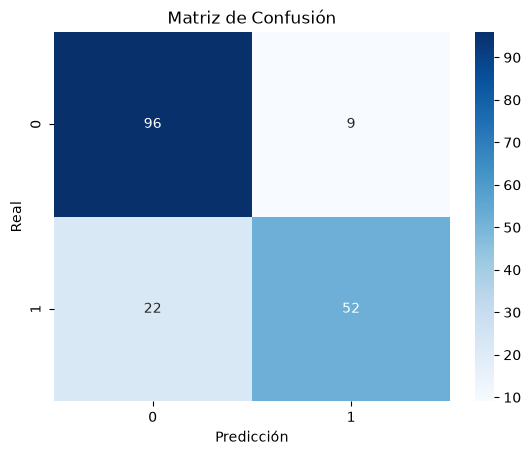

              precision    recall  f1-score   support

           0       0.81      0.91      0.86       105
           1       0.85      0.70      0.77        74

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.82       179



In [44]:
#Matriz de confusion.
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()
print(classification_report(y_test, y_pred))

Conclusion del proyecto:
El modelo de clasificación que entrené para el proyecto del Titanic mostró un desempeño sólido y consistente. Con un accuracy del 82%, y métricas equilibradas entre ambas clases (precision y recall alrededor de 0.80 a 0.87), el modelo logró identificar correctamente la mayoría de los casos tanto de sobrevivientes como de no sobrevivientes. La matriz de confusión confirma que el modelo es especialmente fuerte prediciendo la clase 0, aunque también mantiene un buen rendimiento con la clase 1.

Reflexion:
Después de completar este trabjo, me doy cuenta de que aunque el notebook funciona bien para entrenar un modelo y evaluar métricas, en un entorno real sería necesario aplicar prácticas de MLOps para que el sistema sea confiable y útil a largo plazo. Por ejemplo, en mi área profesional trabajamos con motores, bombas y maquinaria pesada que cambia su comportamiento con el tiempo. Un motor nuevo puede consumir 30 A de corriente, pero conforme se desgasta empieza a subir gradualmente a 32 A, 34 A o más. Ese aumento es una señal clara de que algo está cambiando y podría fallar pronto. Un modelo entrenado con datos históricos puede detectar estas variaciones, pero si no se actualiza, eventualmente dejará de ser preciso porque la “normalidad” del motor ya no es la misma.
Aquí es donde MLOps se vuelve esencial: pipelines automáticos para limpiar datos, validación continua, monitoreo de drift y reentrenamiento periódico. Estas prácticas permiten que un modelo predictivo realmente funcione en producción y no se quede obsoleto. En mi trabajo, esto se traduce en menos fallas inesperadas, mejor planificación de mantenimiento y decisiones basadas en datos reales.
